# 02 · HTTP, sesión y tiempo real

[Índice del frontend](README.md) · [Anterior · Arquitectura y reactividad](01_arquitectura_y_reactividad.ipynb) · [Siguiente · Series, historial y CSV](03_series_historial_y_csv.ipynb)

## HTTP desde el navegador

HTTP se organiza en peticiones y respuestas. Una petición tiene método, destino y, cuando corresponde,
encabezados y cuerpo. El estado de respuesta indica si se pudo realizar la operación. El frontend usa
`fetch` para peticiones finitas de autenticación y consulta, y `EventSource` para escuchar eventos
durante una conexión HTTP abierta.

Un **origen** reúne protocolo, host y puerto. `http://127.0.0.1:5173` y `http://127.0.0.1:8000`
son orígenes distintos por su puerto. En desarrollo, el navegador pide `/api/...` al origen de Vite.
El proxy Vite lo reenvía desde el servidor hacia el destino configurado. Esto conserva una sola dirección
visible desde el navegador y permite que sus peticiones relativas operen con las cookies del host vigente.
Aunque la coincidencia de cookies se decide por reglas como host y ruta, el aislamiento JavaScript de
origen incorpora el puerto. Usa el mismo host en toda la sesión y evita alternar entre `localhost`
y `127.0.0.1`.

`models/api.js` añade `/api`, transforma errores de HTTP en `ApiError` y analiza el JSON cuando hay contenido.
Para `204 No Content`, termina sin intentar decodificar el cuerpo. `postJson` serializa el cuerpo y lo marca
con `Content-Type: application/json`.

[Cliente HTTP](../../frontend/src/models/api.js)

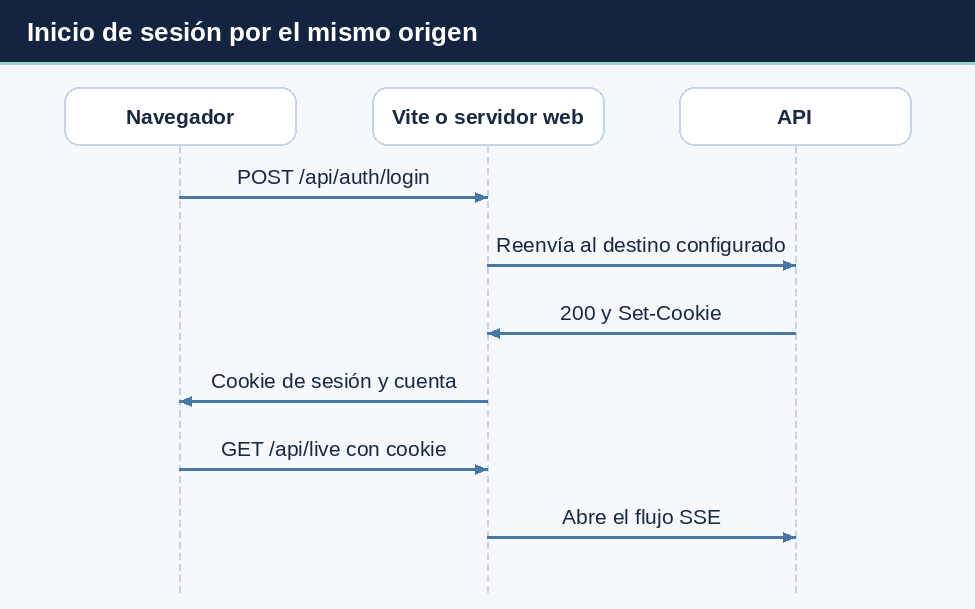

## Sesión y credenciales

| Operación | Petición | Comportamiento en pantalla |
| --- | --- | --- |
| Cargar o recuperar sesión | `GET /api/auth/me` | Con la cuenta válida abre el dashboard. Con `401` abre el acceso. |
| Iniciar | `POST /api/auth/login` con `username` y `password` en JSON | Con éxito guarda el usuario mostrado. Con `401` o `422` pide revisar las credenciales. |
| Cerrar | `POST /api/auth/logout` | Con `204` desmonta el dashboard y vuelve al acceso. |
| Leer datos en vivo | `GET /api/live` | Escucha snapshots durante una sesión válida. |

La API responde a un acceso correcto con una cookie de sesión. En este proyecto contiene un JWT,
un dato firmado por el servidor que representa una sesión con caducidad. El atributo `HttpOnly`
impide leer la cookie con JavaScript. El navegador se encarga de adjuntarla en solicitudes válidas al
mismo origen. La cookie aplica en la ruta `/api`, usa `SameSite=Strict` y puede llevar `Secure` cuando
se configura HTTPS. La variable reactiva `user` guarda la información de la cuenta visible en la interfaz.

Tras un cambio de sesión, una respuesta `401` en consultas protegidas hace que el dashboard notifique
al componente raíz y aparezca el formulario. Un `422` indica que la API rechazó los valores recibidos.
Un fallo de red ocurre antes de disponer de un estado HTTP. Los tres casos requieren interpretaciones
distintas al diagnosticar el acceso.

[Gestión de sesión en App.svelte](../../frontend/src/App.svelte)

## Server-Sent Events y snapshot

SSE usa una respuesta HTTP cuyo tipo es `text/event-stream`. El servidor envía texto UTF-8 dentro de
esa misma respuesta. Una línea como `event: snapshot` asigna nombre al evento. Una línea `data:`
contiene su contenido. Una línea vacía cierra el evento. El navegador agrupa el texto y dispara el callback
de `addEventListener('snapshot', ...)`. El JavaScript analiza `data` como JSON.

```text
event: snapshot
data: {"broker_connected":true,"devices":[{"device_id":"ESP32_S3_0001","status":"conectado","latest":null}]}
```

El ejemplo muestra un dispositivo en estado conectado cuya última lectura todavía no existe.
Cada snapshot representa un conjunto completo de estados visibles. El dashboard reemplaza el arreglo
`devices` y conserva la selección si el identificador sigue presente. Una lectura disponible incluye
campos como `measured_at`, `received_at`, `temperature`, `humidity`, `gas` y `calibrated`.
Cada indicador puede estar ausente en una lectura y se presenta como `—`.

SSE va del servidor al navegador. Los clics, filtros y demás operaciones del usuario usan mecanismos
separados como `fetch` o la descarga mediante un enlace. Las tarjetas se actualizan desde el snapshot.
Las gráficas consultan otro endpoint y su refresco tiene un intervalo propio.

## Conexión, estado y recuperación

| Señal | Valor observado | Qué significa para el panel |
| --- | --- | --- |
| Conexión SSE | `connecting`, `open`, `reconnecting` en la vista | Indica si el navegador recibe el flujo HTTP. |
| Comunicación de la API con el broker | `broker_connected` | La etiqueta MQTT se muestra con el flujo HTTP abierto. |
| Estado de un dispositivo | `conectado`, `desconectado` o sin estado | Identifica lo que se sabe de ese dispositivo. |
| Última muestra | `measured_at` o `received_at` | Ayuda a detectar cuán reciente es el dato presentado. |

Si el flujo falla, `Dashboard.svelte` consulta `/api/auth/me` con una sola comprobación en curso.
Si recibe `401` mientras sigue montado, informa la expiración. El navegador puede reconectar por su cuenta
mientras `EventSource` siga intentando. Si la conexión alcanza `EventSource.CLOSED` y la vista sigue activa,
el código programa una nueva instancia tras tres segundos. Al desmontar se cierra el flujo y se cancela
el temporizador. Así, volver a entrar abre una conexión nueva sin conservar la anterior.

Una persona puede ver **MQTT desconectado** con el flujo HTTP abierto. Ese estado comunica una falla posterior
en la ruta de las mediciones. **Reconectando al panel** informa que el navegador perdió la conexión al endpoint
HTTP. Observa ambos estados junto con la hora de la última muestra para encontrar el punto observado del problema.

[Flujo en Dashboard.svelte](../../frontend/src/GUI/views/Dashboard.svelte)

## Ejercicio en DevTools

Con una sesión de prueba, abre **Red** y busca la fila `/api/live`. Mantén la pestaña abierta mientras
entra una lectura. La petición pendiente es esperada en SSE. Busca la sección de eventos si tu navegador
la ofrece. Luego cambia de sección dentro del dashboard y verifica que el flujo continúa. Al cerrar sesión,
el dashboard se desmonta y la conexión termina. Los valores de cookies de pruebas se mantienen dentro de
DevTools.

[Índice del frontend](README.md) · [Anterior · Arquitectura y reactividad](01_arquitectura_y_reactividad.ipynb) · [Siguiente · Series, historial y CSV](03_series_historial_y_csv.ipynb)